# M7b · G_eff re-analysis (no training)

**Why this notebook.** M7 reported Pearson **−0.77** between G_eff / |S| and mean OOD video AUC. That looks like “more equal weights → worse OOD,” which is the opposite of the original claim. It is almost certainly a **composition confound**: NeuralTextures is both (i) the generator with the smallest geometric weight whenever it is in the pool, and (ii) the uniquely hard unseen generator. Including NT lowers G_eff / |S| *and* removes NT from OOD (so OOD looks easy). Excluding NT raises G_eff / |S| *and* puts NT in OOD (so OOD looks hard).

**What M7b does.** Read `runs/m7/geff_law.json` (already on C-DAC). No model, no GPU, no new training. Split the 25 subsets by whether NT is in the training set; residualize OOD on *which* generators are held out; report each generator’s geometric weight when it is present; and, for each held-out generator, plot that generator’s AUC against the training subset’s G_eff.

**What a supported claim looks like after this.** “NT is systematically under-weighted in pooled LN tuning” — not “G_eff predicts OOD.”

| Section | What it does | Run time |
|---|---|---|
| 1 | load JSON, rebuild tables | seconds |
| 2 | NT in vs out; raw correlation | seconds |
| 3 | residualize OOD on held-out identity | seconds |
| 4 | per-generator OOD vs G_eff | seconds |
| 5 | geometric weights when present | seconds |
| 6 | paper-ready summary | seconds |

## 1. Load M7 measurements

In [1]:
# 1. Load
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
LAW_JSON = DATA_ROOT / "runs" / "m7" / "geff_law.json"
OUT_DIR = DATA_ROOT / "runs" / "m7b"
OUT_DIR.mkdir(parents=True, exist_ok=True)

ALL = ["DF", "F2F", "FS", "NT", "FSh"]
assert LAW_JSON.exists(), f"missing {LAW_JSON} (run M7 first)"

raw = json.loads(LAW_JSON.read_text())
print(f"loaded {len(raw)} subsets from {LAW_JSON}")


def train_gens(tag):
    return tag.split("+")


def held_gens(tag):
    return [g for g in ALL if g not in train_gens(tag)]


rows = []
for r in raw:
    tag = r["subset"]
    train = train_gens(tag)
    held = held_gens(tag)
    rows.append({
        "subset": tag,
        "size": int(r["size"]),
        "G_eff": float(r["G_eff"]),
        "G_eff/|S|": float(r["G_eff/|S|"]),
        "explained": float(r["explained"]),
        "seen AUC": float(r["seen AUC"]),
        "OOD mean AUC": float(r["OOD mean AUC"]),
        "NT in train": "NT" in train,
        "held": "+".join(held),
        "n_held": len(held),
        "weights": r["weights"],
        "OOD each": r["OOD each"],
        "sum_w_raw": float(r.get("sum_w_raw", float("nan"))),
    })
df = pd.DataFrame(rows)
display(df[["subset", "size", "G_eff/|S|", "explained", "seen AUC", "OOD mean AUC", "NT in train", "held"]].round(3))

loaded 25 subsets from /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m7/geff_law.json


,subset,size,G_eff/|S|,explained,seen AUC,OOD mean AUC,NT in train,held
0,DF+F2F+FS+NT,4,0.659,0.660,96.406,90.531,True,FSh
1,DF+F2F+FS+FSh,4,0.979,0.705,99.147,64.403,False,NT
2,DF+F2F+NT+FSh,4,0.628,0.702,95.013,97.898,True,FS
3,DF+FS+NT+FSh,4,0.715,0.713,91.936,85.403,True,F2F
4,F2F+FS+NT+FSh,4,0.604,0.697,94.421,99.214,True,DF
5,DF+F2F+FS,3,0.981,0.739,99.463,80.444,False,NT+FSh
6,DF+F2F+NT,3,0.607,0.709,96.842,92.429,True,FS+FSh
7,DF+F2F+FSh,3,0.998,0.723,99.007,83.023,False,FS+NT
8,DF+FS+NT,3,0.871,0.745,94.043,92.946,True,F2F+FSh
9,DF+FS+FSh,3,0.996,0.770,99.599,68.893,False,F2F+NT


## 2. The confound: NT in the pool vs NT held out

If the −0.77 is a law about dominance, it should survive after splitting on NT. If it is composition, the two groups sit in different corners of the scatter plot and the correlation inside each group is small.

,n,mean G_eff/|S|,mean OOD,corr vs OOD
group,,,,
all 25 subsets,25,0.824,86.767,-0.768
NT in training set,14,0.696,92.949,-0.429
NT held out of training,11,0.987,78.898,0.239


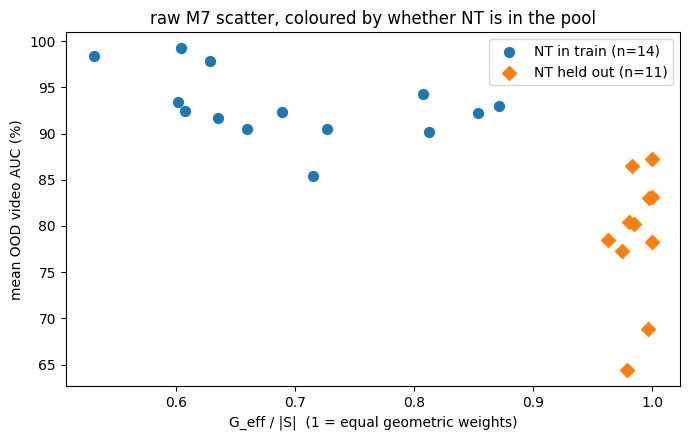

raw correlation, all subsets: -0.768


In [2]:
# 2. NT split
def corr(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    if len(a) < 3 or a.std() == 0 or b.std() == 0:
        return float("nan")
    return float(np.corrcoef(a, b)[0, 1])


overall = corr(df["G_eff/|S|"], df["OOD mean AUC"])
with_nt = df[df["NT in train"]]
no_nt = df[~df["NT in train"]]

split = pd.DataFrame([
    {"group": "all 25 subsets", "n": len(df),
     "mean G_eff/|S|": df["G_eff/|S|"].mean(), "mean OOD": df["OOD mean AUC"].mean(),
     "corr vs OOD": overall},
    {"group": "NT in training set", "n": len(with_nt),
     "mean G_eff/|S|": with_nt["G_eff/|S|"].mean(), "mean OOD": with_nt["OOD mean AUC"].mean(),
     "corr vs OOD": corr(with_nt["G_eff/|S|"], with_nt["OOD mean AUC"])},
    {"group": "NT held out of training", "n": len(no_nt),
     "mean G_eff/|S|": no_nt["G_eff/|S|"].mean(), "mean OOD": no_nt["OOD mean AUC"].mean(),
     "corr vs OOD": corr(no_nt["G_eff/|S|"], no_nt["OOD mean AUC"])},
]).set_index("group")
display(split.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(with_nt["G_eff/|S|"], with_nt["OOD mean AUC"], label=f"NT in train (n={len(with_nt)})", s=50)
ax.scatter(no_nt["G_eff/|S|"], no_nt["OOD mean AUC"], label=f"NT held out (n={len(no_nt)})", s=50, marker="D")
ax.set_xlabel("G_eff / |S|  (1 = equal geometric weights)")
ax.set_ylabel("mean OOD video AUC (%)")
ax.set_title("raw M7 scatter, coloured by whether NT is in the pool")
ax.legend()
plt.tight_layout()
plt.show()
print(f"raw correlation, all subsets: {overall:.3f}")

## 3. Residualize OOD on which generators are held out

OOD mean ≈ average difficulty of the held-out set. Fit

OOD mean ≈ β0 + Σ_g β_g · 1{g held out}

by least squares. The residual is OOD after removing “which generators were tested.” If G_eff still predicts that residual, dominance has an effect beyond composition. If not, G_eff is not an OOD predictor.

held-out generator coefficients (AUC points added when that generator is in OOD):


,DF,F2F,FS,NT,FSh
beta,4.32,-2.48,4.17,-12.88,2.55


fraction of OOD variance explained by which generators are held out: 0.795
corr(G_eff/|S|, OOD mean):      -0.768
corr(G_eff/|S|, OOD residual):  0.007


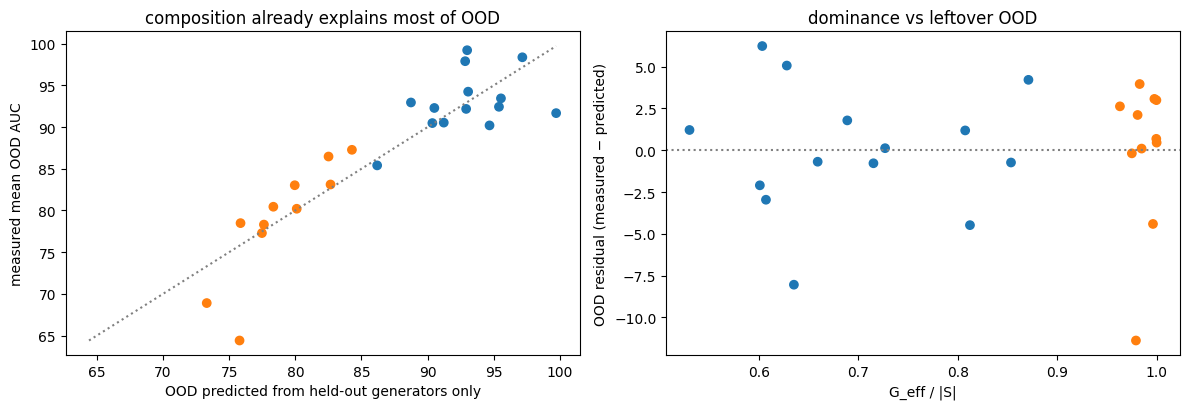

In [3]:
# 3. Residualize on held-out identity
X = np.column_stack([
    np.ones(len(df)),
    np.array([[g in held_gens(tag) for g in ALL] for tag in df["subset"]], dtype=float),
])
y = df["OOD mean AUC"].to_numpy(float)
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
yhat = X @ beta
resid = y - yhat
df = df.copy()
df["OOD predicted by held-out gens"] = yhat
df["OOD residual"] = resid

r_raw = corr(df["G_eff/|S|"], df["OOD mean AUC"])
r_resid = corr(df["G_eff/|S|"], df["OOD residual"])
comp_r2 = 1 - np.var(resid) / np.var(y)

print("held-out generator coefficients (AUC points added when that generator is in OOD):")
display(pd.Series(beta[1:], index=ALL, name="beta").to_frame().T.round(2))
print(f"fraction of OOD variance explained by which generators are held out: {comp_r2:.3f}")
print(f"corr(G_eff/|S|, OOD mean):      {r_raw:.3f}")
print(f"corr(G_eff/|S|, OOD residual):  {r_resid:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(yhat, y, c=df["NT in train"].map({True: "C0", False: "C1"}))
lo, hi = float(min(y.min(), yhat.min())), float(max(y.max(), yhat.max()))
axes[0].plot([lo, hi], [lo, hi], color="gray", linestyle=":")
axes[0].set_xlabel("OOD predicted from held-out generators only")
axes[0].set_ylabel("measured mean OOD AUC")
axes[0].set_title("composition already explains most of OOD")
axes[1].scatter(df["G_eff/|S|"], resid, c=df["NT in train"].map({True: "C0", False: "C1"}))
axes[1].axhline(0, color="gray", linestyle=":")
axes[1].set_xlabel("G_eff / |S|")
axes[1].set_ylabel("OOD residual (measured − predicted)")
axes[1].set_title("dominance vs leftover OOD")
plt.tight_layout()
plt.show()

## 4. Each held-out generator on its own

For generator g, take every subset that does **not** contain g, and plot g’s own video AUC against that subset’s G_eff / |S|. Five small plots: if dominance hurt that unseen generator, the slope would be positive (higher G_eff / |S| → higher AUC on g). Size-4 points are the leave-one-out folds from M5 (pooled, λ = ∞).

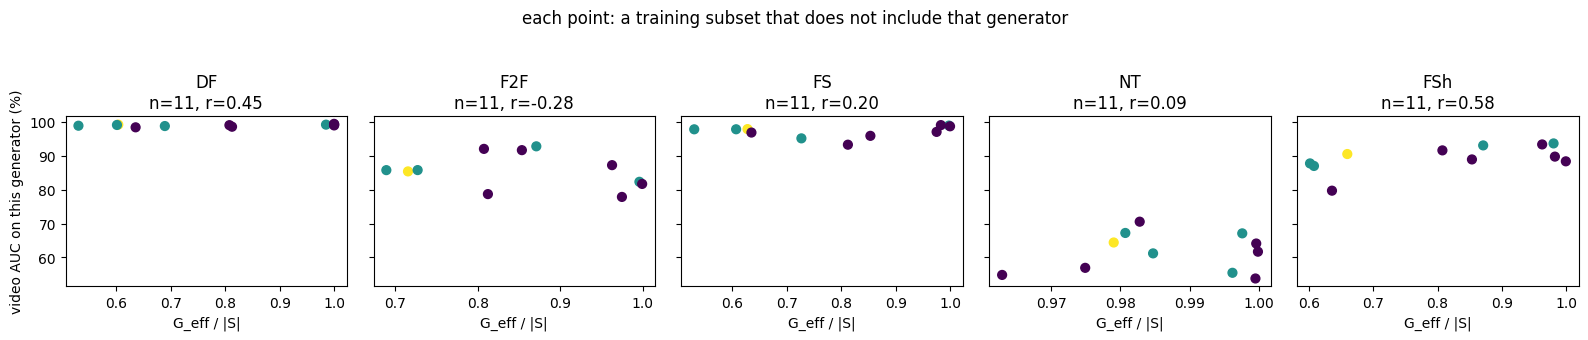

,n,mean_AUC,min_AUC,max_AUC,corr_with_Geff
held out,,,,,
DF,11,99.003,98.423,99.444,0.453
F2F,11,85.578,77.862,92.811,-0.285
FS,11,97.149,93.291,99.077,0.202
NT,11,61.565,53.770,70.551,0.088
FSh,11,89.439,79.709,93.668,0.584


In [4]:
# 4. Per held-out generator
records = []
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharey=True)
for ax, g in zip(axes, ALL):
    xs, ys, sizes = [], [], []
    for r in rows:
        if g in r["OOD each"]:
            xs.append(r["G_eff/|S|"])
            ys.append(r["OOD each"][g])
            sizes.append(r["size"])
            records.append({"held out": g, "subset": r["subset"], "size": r["size"],
                            "G_eff/|S|": r["G_eff/|S|"], "AUC on held-out": r["OOD each"][g]})
    xs, ys, sizes = np.array(xs), np.array(ys), np.array(sizes)
    ax.scatter(xs, ys, c=sizes, cmap="viridis", vmin=2, vmax=4, s=40)
    rho = corr(xs, ys)
    ax.set_title(f"{g}\nn={len(xs)}, r={rho:.2f}")
    ax.set_xlabel("G_eff / |S|")
    if g == "DF":
        ax.set_ylabel("video AUC on this generator (%)")
plt.suptitle("each point: a training subset that does not include that generator", y=1.05)
plt.tight_layout()
plt.show()

per = pd.DataFrame(records)
summary_rows = []
for g in ALL:
    sub = per[per["held out"] == g]
    summary_rows.append({
        "held out": g,
        "n": len(sub),
        "mean_AUC": sub["AUC on held-out"].mean(),
        "min_AUC": sub["AUC on held-out"].min(),
        "max_AUC": sub["AUC on held-out"].max(),
        "corr_with_Geff": corr(sub["G_eff/|S|"], sub["AUC on held-out"]),
    })
summary = pd.DataFrame(summary_rows).set_index("held out")
display(summary.round(3))

## 5. Geometric weights when a generator is in the pool

For each generator g, the distribution of its normalised geometric weight over subsets that contain g. Equal share is 1/|S| (0.50, 0.33, 0.25 for sizes 2, 3, 4). NT sitting below that line, consistently, is the dominance result that survives.

,n,mean_weight,mean_vs_equal,min_weight,max_weight,frac_below_equal
generator,,,,,,
DF,14,0.369,0.012,0.189,0.707,0.571
F2F,14,0.497,0.140,0.261,0.879,0.214
FS,14,0.411,0.054,0.233,0.744,0.286
NT,14,0.061,-0.296,-0.089,0.293,1.000
FSh,14,0.448,0.091,0.265,0.740,0.143


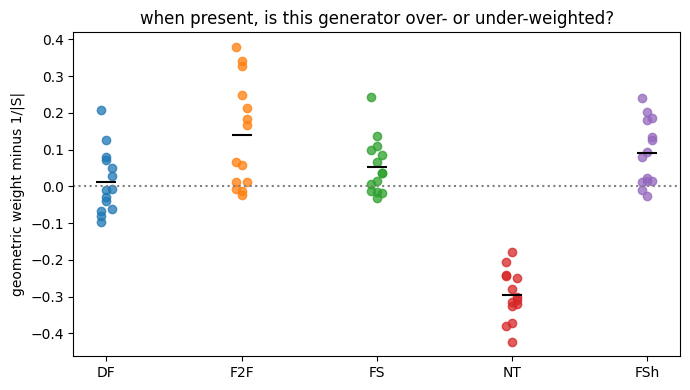

In [5]:
# 5. Weights when present
weight_rows = []
for r in rows:
    S = train_gens(r["subset"])
    equal = 1 / len(S)
    for g, w in r["weights"].items():
        weight_rows.append({
            "generator": g, "subset": r["subset"], "size": r["size"],
            "weight": w, "equal share": equal, "weight − equal": w - equal,
        })
wdf = pd.DataFrame(weight_rows)

wgt = wdf.groupby("generator").agg(
    n=("weight", "size"),
    mean_weight=("weight", "mean"),
    mean_vs_equal=("weight − equal", "mean"),
    min_weight=("weight", "min"),
    max_weight=("weight", "max"),
    frac_below_equal=("weight − equal", lambda s: float((s < 0).mean())),
).reindex(ALL)
display(wgt.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
positions = {g: i for i, g in enumerate(ALL)}
for g in ALL:
    sub = wdf[wdf.generator == g]
    ax.scatter(np.full(len(sub), positions[g]) + 0.04 * (sub["size"] - 3),
               sub["weight"] - sub["equal share"], alpha=0.75, label=None)
    ax.scatter([positions[g]], [sub["weight"].mean() - sub["equal share"].mean()],
               color="black", marker="_", s=200)
ax.axhline(0, color="gray", linestyle=":")
ax.set_xticks(range(len(ALL)), ALL)
ax.set_ylabel("geometric weight minus 1/|S|")
ax.set_title("when present, is this generator over- or under-weighted?")
plt.tight_layout()
plt.show()

## 6. What we can claim

In [6]:
# 6. Summary for the paper
claim = pd.Series({
    "raw corr(G_eff/|S|, OOD mean)": round(r_raw, 3),
    "OOD variance explained by held-out identity": round(comp_r2, 3),
    "corr(G_eff/|S|, OOD residual)": round(r_resid, 3),
    "mean G_eff/|S| when NT in train": round(with_nt["G_eff/|S|"].mean(), 3),
    "mean G_eff/|S| when NT held out": round(no_nt["G_eff/|S|"].mean(), 3),
    "mean OOD when NT in train": round(with_nt["OOD mean AUC"].mean(), 2),
    "mean OOD when NT held out": round(no_nt["OOD mean AUC"].mean(), 2),
    "NT mean (weight − 1/|S|)": round(wgt.loc["NT", "mean_vs_equal"], 3),
    "F2F mean (weight − 1/|S|)": round(wgt.loc["F2F", "mean_vs_equal"], 3),
    "NT fraction of subsets below equal share": round(wgt.loc["NT", "frac_below_equal"], 2),
}, name="value")
display(claim.to_frame())

# supported vs not
print("SUPPORTED: NT is under-weighted relative to 1/|S| in pooled LN tuning.")
print("SUPPORTED: NT as unseen is much harder than DF/FS (size-4 LOGO: NT 64 vs DF 99).")
print("NOT SUPPORTED: G_eff / |S| is a predictor of OOD once held-out identity is accounted for.")

out = {
    "nt_split": split.round(4).to_dict(),
    "residual": {"raw_corr": r_raw, "resid_corr": r_resid, "composition_r2": comp_r2,
                 "held_out_betas": dict(zip(ALL, [float(x) for x in beta[1:]]))},
    "per_held_out": summary.round(4).to_dict(),
    "weights_when_present": wgt.round(4).to_dict(),
    "claim": claim.to_dict(),
}
(OUT_DIR / "m7b_summary.json").write_text(json.dumps(out, indent=1))
df.drop(columns=["weights", "OOD each"]).to_csv(OUT_DIR / "subsets_with_residuals.csv", index=False)
wdf.to_csv(OUT_DIR / "weights_when_present.csv", index=False)
per.to_csv(OUT_DIR / "per_held_out.csv", index=False)
print("wrote", OUT_DIR)

,value
"raw corr(G_eff/|S|, OOD mean)",-0.768
OOD variance explained by held-out identity,0.795
"corr(G_eff/|S|, OOD residual)",0.007
mean G_eff/|S| when NT in train,0.696
mean G_eff/|S| when NT held out,0.987
mean OOD when NT in train,92.950
mean OOD when NT held out,78.900
NT mean (weight − 1/|S|),-0.296
F2F mean (weight − 1/|S|),0.140
NT fraction of subsets below equal share,1.000


SUPPORTED: NT is under-weighted relative to 1/|S| in pooled LN tuning.
SUPPORTED: NT as unseen is much harder than DF/FS (size-4 LOGO: NT 64 vs DF 99).
NOT SUPPORTED: G_eff / |S| is a predictor of OOD once held-out identity is accounted for.
wrote /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m7b
